# KNN Classification — Wholesale Customers
**Learning + portfolio notebook (Google Colab compatible)**

Expected CSV: `multiclass.csv`  
Features: `Region`, `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`  
Target: `class`

Run cells top-to-bottom. Upload the original CSV from your earlier notebook. This notebook explains the workflow; reusable code belongs in `src/`.

## 1. Install and import

In [ ]:
%pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

In [ ]:
# !pip install gdown
# !gdown 1ZdhRqYv-JizWV6DxO6C4R_k1kxPhmlF2 -O multiclass.csv

## 2. Upload the original data

In [ ]:
uploaded = files.upload()
data_path = next(iter(uploaded))
df = pd.read_csv(data_path)
print("Shape:", df.shape)
display(df.head())

Saving multiclass.csv to multiclass (2).csv
Shape: (440, 8)


,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,class
0,3,12669,9656,7561,214,2674,1338,2
1,3,7057,9810,9568,1762,3293,1776,2
2,3,6353,8808,7684,2405,3516,7844,2
3,3,13265,1196,4221,6404,507,1788,1
4,3,22615,5410,7198,3915,1777,5185,1


`files.upload()` opens Colab's file picker. `read_csv()` loads the data. Confirm this is the same dataset used in your original notebook.

## 3. Validate schema and inspect data quality

In [ ]:
# FEATURES = ["Region", "Fresh", "Milk", "Grocery", "Frozen",
#             "Detergents_Paper", "Delicassen"]
# TARGET = "class"
# missing_cols = [c for c in FEATURES + [TARGET] if c not in df.columns]
# if missing_cols:
#     raise ValueError(f"Missing columns: {missing_cols}")
# df = df[FEATURES + [TARGET]].copy()
# display(df.dtypes.to_frame("dtype"))
# display(df.isna().sum().to_frame("missing"))
# print("Exact duplicate rows:", df.duplicated().sum())
# display(df[TARGET].value_counts(dropna=False).to_frame("count"))
FEATURES = ["Region", "Fresh", "Milk", "Grocery", "Frozen",
           "Detergents_Paper", "Delicassen"]
TARGET = "class"
missing_cols = [c for c in FEATURES + [TARGET] if c not in df.columns]
if missing_cols:
  raise ValueError(f"Missing columns : {missing_cols}")
df = df[FEATURES + [TARGET]].copy()
display(df.dtypes.to_frame("dtype"))
display(df.isna().sum().to_frame("missing"))
print("Exact duplicate rows :", df.duplicated().sum())
display(df[TARGET].value_counts(dropna=False).to_frame("count"))


,dtype
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64
class,int64


,missing
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0
class,0


Exact duplicate rows : 0


,count
class,
2,180
3,173
1,87


**Why:** validate names, types, missing values and class balance before training. Investigate duplicates and outliers rather than deleting them automatically. A missing target cannot be used for supervised learning.

## 4. Explore distributions

,count,mean,std,min,25%,50%,75%,max
Region,440.0,2.543182,0.774272,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.297727,12647.328865,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.265909,7380.377175,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.277273,9503.162829,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.931818,4854.673333,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.493182,4767.854448,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.870455,2820.105937,3.0,408.25,965.5,1820.25,47943.0
class,440.0,2.195455,0.744289,1.0,2.00,2.0,3.00,3.0


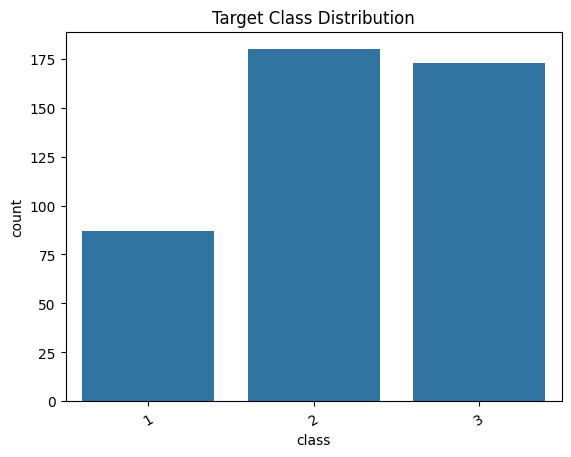

In [ ]:
display(df.describe(include="all").T)
sns.countplot(data=df, x=TARGET)
plt.title("Target Class Distribution")
plt.xticks(rotation=30)
plt.show()

Look for skewed spending variables and rare classes. EDA should guide hypotheses; it does not automatically justify removing observations.

## 5. Split data before preprocessing

In [ ]:
from sklearn.model_selection import train_test_split
X = df[FEATURES].copy()
y = df[TARGET].copy()
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)
display(y_train.value_counts(normalize=True).sort_index()
        )

Train: (330, 7) Test: (110, 7)


,proportion
class,
1,0.196970
2,0.409091
3,0.393939


`stratify=y` approximately preserves class proportions. The test set must not be used for tuning. A 75/25 split is a teaching choice, not an industry law. Use group/time splits if the real data has repeated customers or temporal structure.

## 6. Build a leakage-safe preprocessing + KNN pipeline

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
NUMERIC = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
CATEGORICAL = ["Region"]
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
category_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer([
    ("numeric", numeric_pipe, NUMERIC),
    ("categorical", category_pipe, CATEGORICAL)
])
knn_pipe = Pipeline([
    ("preprocess", preprocess),
    ("knn", KNeighborsClassifier())
])
knn_pipe

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Fresh', 'Milk', 'Grocery',
                                                   'Frozen', 'Detergents_Paper',
                                                   'Delicassen']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Region'])])),
                ('knn', KNeighborsClassifier())])

**Why this design?**
- KNN relies on distances, so spending columns need comparable scales.
- `Region` is categorical; its numeric code should not automatically be interpreted as a meaningful distance.
- The imputer/scaler/encoder are fitted within each training fold because they live inside the pipeline. This prevents preprocessing leakage during cross-validation.

## 7. Establish a simple baseline

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_test)

baseline = {
    "accuracy": accuracy_score(y_test, dummy_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, dummy_pred),
    "macro_f1": f1_score(y_test, dummy_pred, average="macro", zero_division=0)
}


pd.Series(baseline, name="Dummy baseline")


,Dummy baseline
accuracy,0.409091
balanced_accuracy,0.333333
macro_f1,0.193548


A baseline answers: does KNN add value beyond always predicting the most frequent class? Macro-F1 weights each class equally; balanced accuracy averages recall across classes.

## 8. Tune KNN using stratified cross-validation

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

min_count = int(y_train.value_counts().min())
folds = min(5, min_count)
if folds < 2:
    raise ValueError("Not enough examples per class for cross-validation.")

cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=42)
k_values = [k for k in [3, 5, 7, 9, 11, 15, 21] if k < len(X_train)] or [1]

search = GridSearchCV(
    knn_pipe,
    {
        "knn__n_neighbors": k_values,
        "knn__weights": ["uniform", "distance"],
        "knn__p": [1, 2]
    },
    scoring="f1_macro", cv=cv, n_jobs=-1, refit=True,
    return_train_score=True
)
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Best parameters:", search.best_params_)
print("Best CV macro-F1:", round(search.best_score_, 4))

Best parameters: {'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV macro-F1: 0.8545


`n_neighbors` is K (number of neighbors voting). `uniform` gives equal votes; `distance` weights closer neighbors more. `p=1` is Manhattan distance; `p=2` is Euclidean distance. Grid search selects settings using training folds only.

## 9. Final evaluation — use the test set once

Baseline: {'accuracy': 0.4090909090909091, 'balanced_accuracy': np.float64(0.3333333333333333), 'macro_f1': 0.19354838709677422}
Accuracy: 0.8909090909090909
Balanced accuracy: 0.8636128729151985
Macro-F1: 0.8684463684463685
              precision    recall  f1-score   support

           1       0.80      0.73      0.76        22
           2       0.98      0.93      0.95        45
           3       0.85      0.93      0.89        43

    accuracy                           0.89       110
   macro avg       0.88      0.86      0.87       110
weighted avg       0.89      0.89      0.89       110



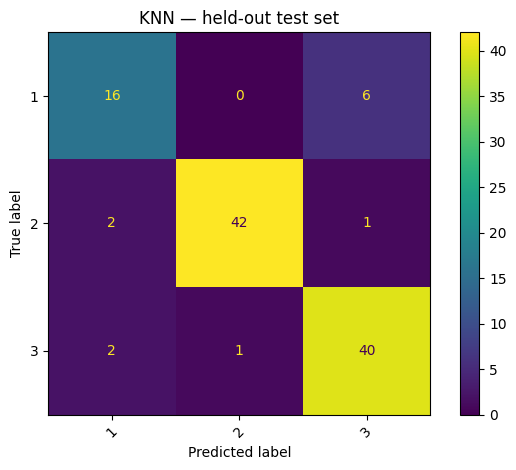

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

pred = best_model.predict(X_test)
print("Baseline:", baseline)
print("Accuracy:", accuracy_score(y_test, pred))
print("Balanced accuracy:", balanced_accuracy_score(y_test, pred))
print("Macro-F1:", f1_score(y_test, pred, average="macro", zero_division=0))
print(classification_report(y_test, pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, pred, xticks_rotation=45)
plt.title("KNN — held-out test set")
plt.tight_layout()
plt.show()

Rows in the confusion matrix are actual classes; columns are predictions. Diagonal = correct predictions; off-diagonal = errors. Explain which classes are confused and why. Do not report only accuracy.

## 10. Inspect CV stability and save artifacts

In [ ]:
cv_results = pd.DataFrame(search.cv_results_)
display(cv_results[[
    "param_knn__n_neighbors", "param_knn__weights", "param_knn__p",
    "mean_test_score", "std_test_score", "mean_train_score"
]].sort_values("mean_test_score", ascending=False).head(15))

,param_knn__n_neighbors,param_knn__weights,param_knn__p,mean_test_score,std_test_score,mean_train_score
1,3,distance,1,0.854515,0.074269,1.000000
23,15,distance,2,0.846317,0.037367,1.000000
0,3,uniform,1,0.845901,0.066209,0.908554
5,5,distance,1,0.845377,0.031579,1.000000
4,5,uniform,1,0.845351,0.026562,0.904993
15,9,distance,2,0.844526,0.038580,1.000000
6,5,uniform,2,0.841311,0.052098,0.911848
22,15,uniform,2,0.840953,0.016610,0.862460
19,11,distance,2,0.838469,0.045449,1.000000
8,7,uniform,1,0.838359,0.027189,0.886666


In [ ]:
from pathlib import Path
import json, joblib

Path("artifacts").mkdir(exist_ok=True)
joblib.dump(best_model, "artifacts/knn_model.joblib")
metrics = {
    "best_params": search.best_params_,
    "cv_macro_f1": float(search.best_score_),
    "test_accuracy": float(accuracy_score(y_test, pred)),
    "test_balanced_accuracy": float(balanced_accuracy_score(y_test, pred)),
    "test_macro_f1": float(f1_score(y_test, pred, average="macro", zero_division=0)),
    "baseline": {k: float(v) for k, v in baseline.items()}
}
with open("artifacts/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
print(metrics)

{'best_params': {'knn__n_neighbors': 3, 'knn__p': 1, 'knn__weights': 'distance'}, 'cv_macro_f1': 0.854514622713759, 'test_accuracy': 0.8909090909090909, 'test_balanced_accuracy': 0.8636128729151985, 'test_macro_f1': 0.8684463684463685, 'baseline': {'accuracy': 0.4090909090909091, 'balanced_accuracy': 0.3333333333333333, 'macro_f1': 0.19354838709677422}}


Save the full pipeline so future predictions use identical preprocessing. Only load joblib/pickle files from trusted sources. Track data version, code commit, package versions, seed and metrics.

## 11. Sample prediction

In [ ]:
sample = X_train.iloc[[0]].copy()
print("Input:")
display(sample)
print("Predicted class:", best_model.predict(sample)[0])
print("Class order:", best_model.named_steps["knn"].classes_)
print("Probabilities:", best_model.predict_proba(sample)[0])

Input:


,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
254,1,10379,17972,4748,4686,1547,3265


Predicted class: 2
Class order: [1 2 3]
Probabilities: [0. 1. 0.]


## 12. Write your findings

Based on our experiments, here are the documented findings:

- **Row count and class distribution:**
  - Total rows: 440
  - Class 1: 87 samples
  - Class 2: 180 samples
  - Class 3: 173 samples
- **Baseline macro-F1:** ~0.1935 (Dummy classifier predicting the most frequent class)
- **Best K and distance settings:** K = 3, Manhattan distance (`p=1`), and weights weighted by `distance`.
- **Best cross-validation macro-F1:** ~0.8545
- **Held-out test macro-F1:** ~0.8684
- **Classes most often confused:** Class 1 was most often confused with Class 3 (6 instances where Class 1 was predicted as Class 3).
- **Whether KNN beat the baseline:** Yes, KNN significantly outperformed the baseline, improving macro-F1 from 0.1935 to 0.8684.


## 13. Notebook vs production code — industry practice

Use notebooks for EDA, plots, experiments and communicating findings. Keep reusable training/inference logic in tested Python modules under `src/`. Avoid maintaining two different implementations.

Recommended GitHub layout:
- `notebooks/` — exploration and explanation;
- `src/` — reusable training and inference code;
- `tests/` — automated tests;
- `data/` — local data, normally git-ignored unless redistribution is permitted;
- `README.md` — reproducible setup, methodology, results and limitations;
- `.github/workflows/` — CI checks;
- model artifacts — external storage or a model registry as the project grows.

Commit the notebook and code, not private/restricted data or secrets. Clear bulky notebook outputs before committing.